# 01 — Exploration des performances des réseaux d’eau potable

**Problématique :** *Est-il possible de prédire le rendement d'un réseau de distribution d'eau potable à partir de ses caractéristiques géographiques, de son volume d'eau et de son mode de gestion ?*

Ce notebook porte sur l'**exploration**. La modélisation et la séparation entraînement/test seront traitées ensuite.

## 1. Bibliothèques

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Chargement des données

Le fichier est séparé par des points-virgules. Nous conservons les identifiants comme du texte pour ne pas perdre les zéros initiaux.

In [6]:
chemin = Path("../data/reseaux-performances-2014-2022.csv")
if not chemin.exists():
    chemin = Path("data/reseaux-performances-2014-2022.csv")

df = pd.read_csv(
    "../data/reseaux-performances-2014-2022.csv",
    sep=";",
    decimal=","
)
print("Dimensions :", df.shape)
df.head()

Dimensions : (13647, 25)


,ANNEE,N_RESEAU,RESEAU,RESEAU_DETAIL,RESEAU_INSEE,RESEAU_COMMUNE REFERENCE,RESEAU_DPT_CODE,RESEAU_DEPARTEMENT,RESEAU_REGION_CODE,RESEAU_REGION,...,EXPLOITANT_COMMUNE,EXPLOITANT_DPT_CODE,EXPLOITANT_DEPARTEMENT,EXPLOITANT_REGION_CODE,EXPLOITANT_REGION,Volume réseau (m3),Indice,Rendement,Plan d’action (O/N),ILC
0,2014,002000129,BUCY-LES-PIERREPONT,BUCY-LES-PIERREPONT,2133,BUCY-LES-PIERREPONT,2,AISNE,32,HAUTS-DE-FRANCE,...,Bucy-lès-Pierrepont,2,AISNE,32,HAUTS-DE-FRANCE,NaN,82.0,73.00,N,11.28
1,2015,002000401,VAUXCERE,VAUXCERE,2771,VAUXCERE,2,AISNE,32,HAUTS-DE-FRANCE,...,SEPTVALLONS,2,AISNE,32,HAUTS-DE-FRANCE,11061.0,83.0,42.69,NaN,16.17
2,2015,002001370,SYNDICAT DES EAUX DE GLENNES ET REVILLON,SYNDICAT DES EAUX DE GLENNES ET REVILLON,2348,GLENNES,2,AISNE,32,HAUTS-DE-FRANCE,...,SEPTVALLONS,2,AISNE,32,HAUTS-DE-FRANCE,17394.0,83.0,57.20,NaN,6.49
3,2014,002003777,LA MALMAISON,LA MALMAISON,2454,LA MALMAISON,2,AISNE,32,HAUTS-DE-FRANCE,...,Malmaison,2,AISNE,32,HAUTS-DE-FRANCE,22150.0,92.0,78.10,O,18.96
4,2014,008000843,LE THOUR,LE THOUR,8451,LE THOUR,8,ARDENNES,44,GRAND EST,...,Thour,8,ARDENNES,44,GRAND EST,20852.0,10.0,54.00,NaN,NaN


## 3. Structure et types des variables

In [7]:
df.info()
print("Colonnes :")
print(df.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 13647 entries, 0 to 13646
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ANNEE                     13647 non-null  int64  
 1   N_RESEAU                  13647 non-null  str    
 2   RESEAU                    13647 non-null  str    
 3   RESEAU_DETAIL             13647 non-null  str    
 4   RESEAU_INSEE              13647 non-null  int64  
 5   RESEAU_COMMUNE REFERENCE  13647 non-null  str    
 6   RESEAU_DPT_CODE           13647 non-null  int64  
 7   RESEAU_DEPARTEMENT        13647 non-null  str    
 8   RESEAU_REGION_CODE        13647 non-null  str    
 9   RESEAU_REGION             13647 non-null  str    
 10  EXPLOITANT_NAF5_Code      13645 non-null  str    
 11  EXPLOITANT_NAF5_Lib       13645 non-null  str    
 12  EXPLOITANT_CATJUR_CODE    13610 non-null  float64
 13  EXPLOITANT_CAT_JUR_LIB    13610 non-null  str    
 14  EXPLOITANT_INSEE 

## 4. Conversion des variables numériques

Les décimales utilisent parfois une virgule. Les valeurs non convertibles deviennent manquantes.

In [8]:
# Identification des colonnes numériques
colonnes_numeriques = df.select_dtypes(
    include="number"
).columns.tolist()

print("Colonnes numériques :")
print(colonnes_numeriques)

Colonnes numériques :
['ANNEE', 'RESEAU_INSEE', 'RESEAU_DPT_CODE', 'EXPLOITANT_CATJUR_CODE', 'EXPLOITANT_INSEE', 'EXPLOITANT_DPT_CODE', 'EXPLOITANT_REGION_CODE', 'Volume réseau (m3)', 'Indice', 'Rendement', 'ILC']


In [9]:
for colonne in colonnes_numeriques:
    df[colonne] = pd.to_numeric(
        df[colonne].astype("string").str.replace(",", ".", regex=False),
        errors="coerce"
    )
df["ANNEE"] = pd.to_numeric(df["ANNEE"], errors="coerce")
display(df[colonnes_numeriques].describe())

,ANNEE,RESEAU_INSEE,RESEAU_DPT_CODE,EXPLOITANT_CATJUR_CODE,EXPLOITANT_INSEE,EXPLOITANT_DPT_CODE,EXPLOITANT_REGION_CODE,Volume réseau (m3),Indice,Rendement,ILC
count,13647.0,13647.0,13647.0,13610.0,13647.0,13647.0,13647.0,13414.0,13618.0,13616.0,13607.0
mean,2019.634865,46948.604822,46.658386,6390.90022,50227.42251,49.93962,32.87587,725666.477665,85.726533,75.702455,25.683192
std,1.688768,28315.212376,28.331091,1055.169333,27651.897501,27.665172,13.59227,10909161.593336,27.433299,19.195674,676.350078
min,2013.0,2004.0,2.0,1100.0,2004.0,2.0,11.0,0.0,0.0,0.0,0.0
25%,2018.0,21119.5,21.0,5710.0,21438.0,21.0,27.0,15348.5,75.0,69.86,5.0
50%,2020.0,51649.0,51.0,7210.0,52448.0,52.0,28.0,45693.5,93.0,79.4,8.24
75%,2021.0,75056.0,75.0,7346.0,76186.0,76.0,44.0,178118.0,105.0,87.4,13.35
max,2022.0,95676.0,95.0,9300.0,95676.0,95.0,84.0,343474493.0,120.0,114.2,58193.0


## 5. Valeurs manquantes

In [10]:
bilan = pd.DataFrame({
    "Valeurs manquantes": df.isna().sum(),
    "Pourcentage (%)": (100 * df.isna().mean()).round(1)
}).sort_values("Pourcentage (%)", ascending=False)
display(bilan)

,Valeurs manquantes,Pourcentage (%)
Plan d’action (O/N),357,2.6
Volume réseau (m3),233,1.7
EXPLOITANT_CATJUR_CODE,37,0.3
EXPLOITANT_CAT_JUR_LIB,37,0.3
ILC,40,0.3
Rendement,31,0.2
Indice,29,0.2
N_RESEAU,0,0.0
ANNEE,0,0.0
RESEAU_REGION_CODE,0,0.0


## 6. Répartition des observations par année

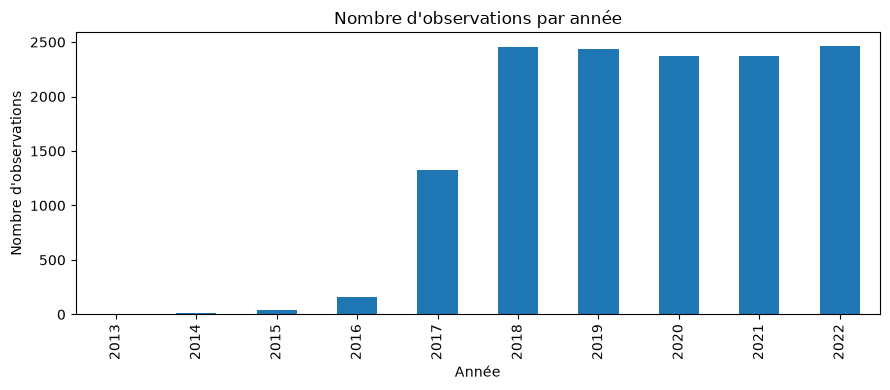

In [11]:
par_annee = df["ANNEE"].value_counts().sort_index()
plt.figure(figsize=(9, 4))
par_annee.plot(kind="bar")
plt.title("Nombre d'observations par année")
plt.xlabel("Année")
plt.ylabel("Nombre d'observations")
plt.tight_layout()
plt.show()

## 7. Distribution du rendement

Les valeurs nulles ou supérieures à 100 % seront examinées : elles ne seront pas effacées automatiquement.

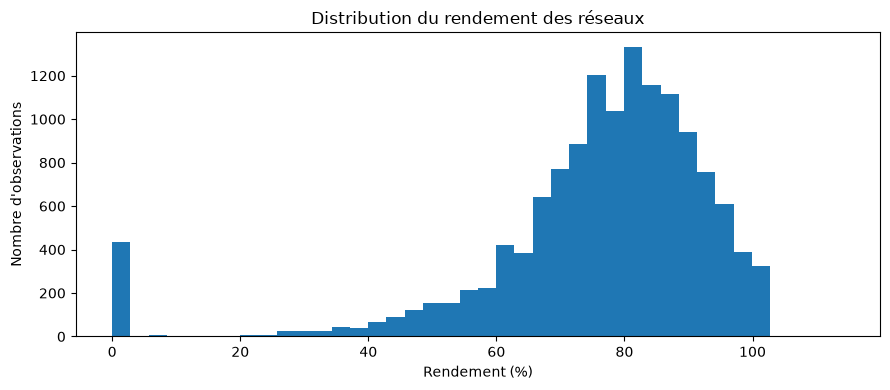

Rendements nuls : 388
Rendements supérieurs à 100 % : 1


In [12]:
plt.figure(figsize=(9, 4))
plt.hist(df["Rendement"].dropna().astype(float), bins=40)
plt.title("Distribution du rendement des réseaux")
plt.xlabel("Rendement (%)")
plt.ylabel("Nombre d'observations")
plt.tight_layout()
plt.show()

print("Rendements nuls :", (df["Rendement"] == 0).sum())
print("Rendements supérieurs à 100 % :", (df["Rendement"] > 100).sum())

## 8. Rendement selon les années

Il s’agit d’une comparaison descriptive. L’échantillon de réseaux peut changer d’une année à l’autre.

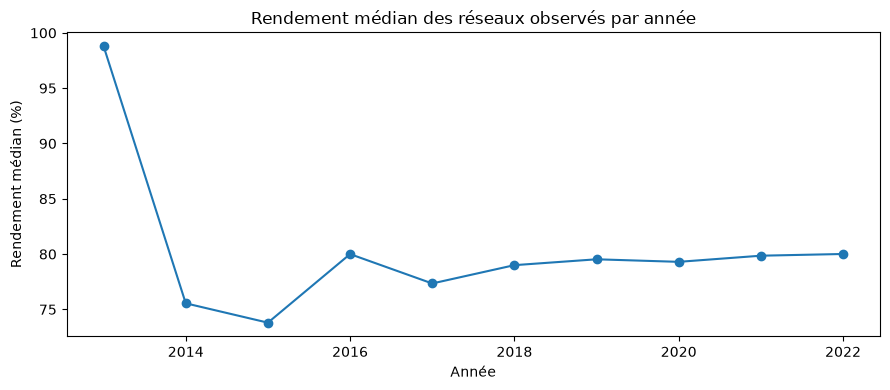

In [13]:
mediane = df.groupby("ANNEE")["Rendement"].median()
plt.figure(figsize=(9, 4))
mediane.plot(marker="o")
plt.title("Rendement médian des réseaux observés par année")
plt.xlabel("Année")
plt.ylabel("Rendement médian (%)")
plt.tight_layout()
plt.show()

## 9. Observations multiples par réseau et année

Avant toute séparation des données, il faut comprendre les lignes portant un même identifiant de réseau et une même année.

In [14]:
cles = ["N_RESEAU", "ANNEE"]
repetitions = df.duplicated(subset=cles, keep=False)
print("Lignes concernées par une répétition réseau-année :", repetitions.sum())
print("Nombre de réseaux différents :", df["N_RESEAU"].nunique())
display(df.loc[repetitions, cles + ["Rendement", "RESEAU"]].sort_values(cles).head(12))

Lignes concernées par une répétition réseau-année : 426
Nombre de réseaux différents : 2942


,N_RESEAU,ANNEE,Rendement,RESEAU
108,1004,2021,74.1,HONFLEUR
109,1004,2021,74.1,HONFLEUR
331,1044,2022,82.51,COPE ARCIS-SUR-AUBE-2858
332,1044,2022,70.7,COPE ARCIS-SUR-AUBE-2858
436,1065,2022,21.99,LANEUVILLE-AU-PONT
437,1065,2022,21.99,LANEUVILLE-AU-PONT
586,1095,2018,27.49,SOREL-MOUSSEL
587,1095,2018,27.49,SOREL-MOUSSEL
643,1105,2022,86.9,COPE MAIZIERES-LA-GRANDE-PAROISSE_2340
644,1105,2022,86.86,COPE MAIZIERES-LA-GRANDE-PAROISSE_2340


## 10. Caractéristiques candidates et fuite d’information

Nous distinguons les variables descriptives de celles qui pourraient être calculées à partir du bilan d’eau ou du rendement.

In [15]:
colonnes_candidates = [
    "ANNEE", "RESEAU_REGION", "RESEAU_DEPARTEMENT",
    "EXPLOITANT_CAT_JUR_LIB"
]
display(df[colonnes_candidates].head())

colonnes_a_verifier = ["Volume réseau (m3)", "Indice", "ILC", "Plan d’action (O/N)"]
print("Indicateurs à vérifier avant utilisation comme prédicteurs :")
print(colonnes_a_verifier)

,ANNEE,RESEAU_REGION,RESEAU_DEPARTEMENT,EXPLOITANT_CAT_JUR_LIB
0,2014,HAUTS-DE-FRANCE,AISNE,Commune et commune nouvelle
1,2015,HAUTS-DE-FRANCE,AISNE,Commune et commune nouvelle
2,2015,HAUTS-DE-FRANCE,AISNE,Commune et commune nouvelle
3,2014,HAUTS-DE-FRANCE,AISNE,Commune et commune nouvelle
4,2014,GRAND EST,ARDENNES,Commune et commune nouvelle


Indicateurs à vérifier avant utilisation comme prédicteurs :
['Volume réseau (m3)', 'Indice', 'ILC', 'Plan d’action (O/N)']


## 11. Bilan provisoire

- La variable cible est `Rendement` : une valeur numérique, adaptée à la régression.
- Le projet vise l’**estimation du rendement de réseaux non observés à l’entraînement**, pas une prédiction chronologique.
- Les enregistrements répétés et les rendements atypiques nécessitent un examen.
- Les indicateurs techniques susceptibles de révéler directement la cible seront exclus tant que leur indépendance n’est pas vérifiée.
- La suite comparera une référence simple, `LinearRegression`, `Ridge` et éventuellement `KNeighborsRegressor` avec `Pipeline`, validation croisée et métriques MAE / R².